# Final Interpretable Model + Diagnostics (County Housing Prices, 2022)

## Interpretable Modeling (Zillow + ACS, 2022)

This notebook builds an interpretable regression model using the same merged county-level dataset constructed in the EDA notebook (`03_housing_price_eda.ipynb`).

To ensure full consistency with the EDA, we reproduce:
- the same county-level merge logic (inner join on standardized 5-digit county FIPS), and
- the same target and predictor transformations (log-transformed ZHVI and log1p population).

The objective is **interpretability**, not causal inference or predictive optimization.


## Imports and Paths

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

BASE_DIR = Path.cwd().parent
PROCESSED_DIR = BASE_DIR / "data" / "processed"


We load the processed Zillow housing price data and the processed ACS county-level feature table.
Both datasets are keyed by standardized 5-digit county FIPS codes.

Raw ACS margins of error are not used because the focus is on interpretable associations rather than survey uncertainty.


In [2]:
ZILLOW_FILE = "zillow_zhvi_2022.csv"
ACS_FILE = "acs_features_2022_county.csv"

zillow = pd.read_csv(PROCESSED_DIR / ZILLOW_FILE)
acs = pd.read_csv(PROCESSED_DIR / ACS_FILE)

zillow.shape, acs.shape


((3061, 4), (3143, 11))

## Merge Zillow and ACS (County Level)

We merge the two datasets using an inner join on county FIPS.
This defines the analysis sample as counties with both:
- observed 2022 housing prices (Zillow), and
- complete socioeconomic characteristics (ACS).

This design ensures that all modeling variables are fully defined.


In [3]:
df = zillow.merge(acs, on="fips", how="inner").copy()

pd.DataFrame({
    "dataset": ["Zillow only", "ACS only", "Merged (inner)"],
    "rows": [len(zillow), len(acs), len(df)]
})


,dataset,rows
0,Zillow only,3061
1,ACS only,3143
2,Merged (inner),3052


In [4]:
df["fips"].nunique(), df.shape[0]


(3052, 3052)

## Schema and Missingness Verification

Before modeling, we verify:
- data types and structure,
- summary statistics,
- absence of missing values.

This ensures that observed modeling results reflect real structure rather than preprocessing artifacts.


In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3052 entries, 0 to 3051
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   fips                       3052 non-null   int64  
 1   State                      3052 non-null   object 
 2   RegionName                 3052 non-null   object 
 3   zhvi_2022                  3052 non-null   float64
 4   county_name                3052 non-null   object 
 5   median_income_2022         3052 non-null   float64
 6   population_2022            3052 non-null   int64  
 7   ba_plus_share_2022         3052 non-null   float64
 8   hs_plus_share_2022         3052 non-null   float64
 9   avg_household_size_2022    3052 non-null   float64
 10  civilian_labor_force_2022  3052 non-null   int64  
 11  employed_2022              3052 non-null   int64  
 12  unemployed_2022            3052 non-null   int64  
 13  unemployment_rate_2022     3052 non-null   float

In [6]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
fips,3052.0,30412.086501,15076.514221,1001.000000,19006.500000,29154.000000,45059.500000,5.604500e+04
zhvi_2022,3052.0,245846.194384,160212.151998,54983.808574,155137.546760,203538.885796,288621.188370,2.756578e+06
median_income_2022,3052.0,63354.721494,16743.250067,24638.000000,52669.500000,60897.000000,70494.750000,1.704630e+05
population_2022,3052.0,107210.935125,337662.449691,416.000000,11735.250000,26791.000000,70106.000000,9.936690e+06
ba_plus_share_2022,3052.0,0.235457,0.100747,0.054205,0.165473,0.209654,0.279175,7.887150e-01
hs_plus_share_2022,3052.0,0.883677,0.055719,0.575814,0.852680,0.895243,0.925244,9.969040e-01
avg_household_size_2022,3052.0,2.507143,0.235457,1.780000,2.360000,2.480000,2.620000,4.360000e+00
civilian_labor_force_2022,3052.0,54321.797182,177507.626874,239.000000,5063.750000,12147.500000,33274.250000,5.235164e+06
employed_2022,3052.0,51432.209371,166673.661635,237.000000,4795.250000,11519.500000,31644.250000,4.869620e+06
unemployed_2022,3052.0,2889.587811,11083.372028,0.000000,232.000000,593.000000,1720.000000,3.655440e+05


## Target and Predictor Transformations

To reduce skewness and support interpretable linear modeling, we apply:

- log_zhvi = log(zhvi_2022)
- log_population = log1p(population_2022)

Coefficients on log-transformed prices can be interpreted approximately in percentage terms.


In [7]:
df["log_zhvi"] = np.log(df["zhvi_2022"])
df["log_population"] = np.log1p(df["population_2022"])

df[["zhvi_2022", "log_zhvi", "population_2022", "log_population"]].head()


,zhvi_2022,log_zhvi,population_2022,log_population
0,822473.001114,13.620071,9936690,16.111745
1,282612.668412,12.551833,5225367,15.469036
2,279352.397555,12.540229,4726177,15.368627
3,483807.870034,13.089443,4430871,15.304107
4,850809.443854,13.653943,3289701,15.006308


In [8]:
df.shape, df["fips"].nunique()


((3052, 16), 3052)

## Step 1. Final Target and Feature Specification

### Final Target (Fixed)

**Target:** `log_zhvi`  
Defined as the natural logarithm of county-level Zillow ZHVI (2022 annual average).

This transformation reduces skewness and allows coefficients to be interpreted in approximate percentage terms.


### Main Features (Final Model Specification)

The following variables define the **official final model**.  
They are chosen for interpretability, stability, and substantive relevance.

- `median_income_2022` (USD, levels)
- `ba_plus_share_2022` (share, 0–1)
- `log_population` (log1p scale)
- `avg_household_size_2022` (levels)
- `unemployment_rate_2022` (rate, 0–1)


### Secondary Feature (Excluded from Final Spec)

- `hs_plus_share_2022`

**Reason:** HS+ is strongly correlated with BA+ and functions as a compositional control.  
Conditional on BA+, HS+ primarily reflects the share of residents with a high school diploma but **without** a bachelor’s degree.  
Including it complicates interpretation and adds limited incremental explanatory value.  
It is therefore evaluated **only as a robustness check**, not as part of the final specification.


In [9]:
TARGET = "log_zhvi"

MAIN_FEATURES = [
    "median_income_2022",
    "ba_plus_share_2022",
    "log_population",
    "avg_household_size_2022",
    "unemployment_rate_2022",
]

SECONDARY_FEATURES = ["hs_plus_share_2022"]

df_model = df[["fips", TARGET] + MAIN_FEATURES + SECONDARY_FEATURES].copy()
df_model.isna().sum()


fips                       0
log_zhvi                   0
median_income_2022         0
ba_plus_share_2022         0
log_population             0
avg_household_size_2022    0
unemployment_rate_2022     0
hs_plus_share_2022         0
dtype: int64

## Step 2. Final Model Estimation (OLS)

This OLS regression is treated as the **official final model** for interpretation.

All coefficients represent **conditional associations**, not causal effects.


In [10]:
y = df_model[TARGET]
X = sm.add_constant(df_model[MAIN_FEATURES])

final_model = sm.OLS(y, X).fit()
final_model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_zhvi   R-squared:                       0.563
Model:                            OLS   Adj. R-squared:                  0.562
Method:                 Least Squares   F-statistic:                     784.0
Date:                Mon, 22 Dec 2025   Prob (F-statistic):               0.00
Time:                        15:53:07   Log-Likelihood:                -843.08
No. Observations:                3052   AIC:                             1698.
Df Residuals:                    3046   BIC:                             1734.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      10.2669      0.070    145.683      0.000      10.129      10.405
median_income_2022       1.163e-05   5.64e-07     20.603      0.000    1.05e-05    1.27e-05
ba_plus_share_2022          1.6815      0.094     17.948      0.000       1.498       1.865
log_population              0.0304      0.005      6.151      0.000       0.021       0.040
avg_household_size_2022     0.2093      0.028      7.604      0.000       0.155       0.263
unemployment_rate_2022      0.8616      0.289      2.980      0.003       0.295       1.428
==============================================================================
Omnibus:                       75.633   Durbin-Watson:                   1.957
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               86.109
Skew:                           0.346   Prob(JB):                     2.00e-19
Kurtosis:                       3.446   Cond. No.                     3.28e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.28e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## Step 3. Coefficient Interpretation

Because the dependent variable is log-transformed, effects are interpreted as:

$$
\% \Delta \text{ZHVI}
\approx
100 \times (\exp(\beta \cdot \Delta X) - 1)
$$

Evaluated at meaningful changes:
- income: +$10,000  
- BA+ share: +10 percentage points  
- population: doubling (Δlog ≈ log(2))  
- household size: +0.5 persons  
- unemployment: +1 percentage point


In [11]:
params = final_model.params

def pct_change(beta, dx):
    return 100 * (np.exp(beta * dx) - 1)

pd.Series({
    "Median income: +$10,000": pct_change(params["median_income_2022"], 10_000),
    "BA+ share: +10 pp": pct_change(params["ba_plus_share_2022"], 0.10),
    "Log population: +1.0": pct_change(params["log_population"], 1.0),
    "Avg household size: +0.5": pct_change(params["avg_household_size_2022"], 0.5),
    "Unemployment rate: +1 pp": pct_change(params["unemployment_rate_2022"], 0.01),
}, name="Approx. % change in ZHVI")


Median income: +$10,000     12.331913
BA+ share: +10 pp           18.311936
Log population: +1.0         3.085099
Avg household size: +0.5    11.033279
Unemployment rate: +1 pp     0.865301
Name: Approx. % change in ZHVI, dtype: float64

**Interpretation highlights**

- Income and BA+ attainment are the strongest correlates of housing prices.
- Population captures urban scale effects.
- Household size shows a moderate positive association.
- Unemployment is weakly related and should be interpreted cautiously as a residual labor-market indicator.


## Step 4. Model Fit and Residual Diagnostics


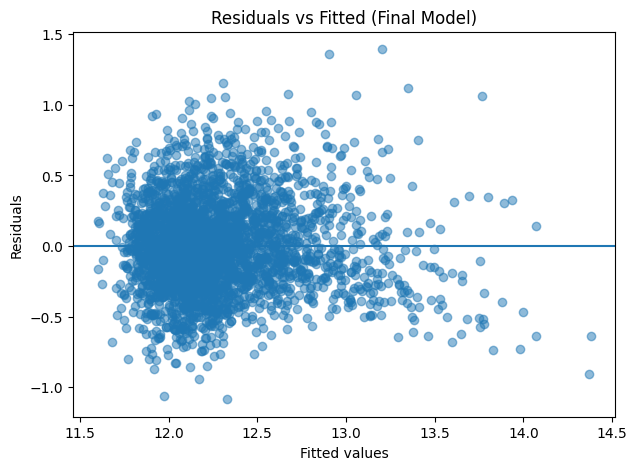

In [12]:
fitted = final_model.fittedvalues
resid = final_model.resid

plt.figure(figsize=(7, 5))
plt.scatter(fitted, resid, alpha=0.5)
plt.axhline(0)
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted (Final Model)")
plt.show()


Residuals show no major nonlinear patterns.  
Mild heteroskedasticity is present but expected in cross-sectional housing data.


## Step 5. Multicollinearity Assessment (VIF)

In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = X.drop(columns="const")

pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i)
            for i in range(X_vif.shape[1])]
})


,Variable,VIF
0,median_income_2022,40.644744
1,ba_plus_share_2022,16.981067
2,log_population,70.256602
3,avg_household_size_2022,58.814741
4,unemployment_rate_2022,7.361054


High VIF values reflect real socioeconomic structure (income, education, urbanization).
Coefficients should be interpreted jointly and conditionally.


## Step 6. Robustness Checks

### Robust Standard Errors (HC3)

HC3 robust standard errors are used to assess sensitivity to heteroskedasticity.


In [14]:
final_model_hc3 = final_model.get_robustcov_results(cov_type="HC3")
final_model_hc3.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_zhvi   R-squared:                       0.563
Model:                            OLS   Adj. R-squared:                  0.562
Method:                 Least Squares   F-statistic:                     561.7
Date:                Mon, 22 Dec 2025   Prob (F-statistic):               0.00
Time:                        15:53:07   Log-Likelihood:                -843.08
No. Observations:                3052   AIC:                             1698.
Df Residuals:                    3046   BIC:                             1734.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      10.2669      0.079    129.761      0.000      10.112      10.422
median_income_2022       1.163e-05   5.86e-07     19.832      0.000    1.05e-05    1.28e-05
ba_plus_share_2022          1.6815      0.112     14.977      0.000       1.461       1.902
log_population              0.0304      0.006      5.247      0.000       0.019       0.042
avg_household_size_2022     0.2093      0.030      6.905      0.000       0.150       0.269
unemployment_rate_2022      0.8616      0.315      2.738      0.006       0.244       1.479
==============================================================================
Omnibus:                       75.633   Durbin-Watson:                   1.957
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               86.109
Skew:                           0.346   Prob(JB):                     2.00e-19
Kurtosis:                       3.446   Cond. No.                     3.28e+06
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
[2] The condition number is large, 3.28e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

All main coefficients remain statistically significant under HC3 robust inference.


### Alternative Specification: Adding HS+ Share

In [15]:
X_hs = sm.add_constant(df_model[MAIN_FEATURES + ["hs_plus_share_2022"]])
model_with_hs = sm.OLS(y, X_hs).fit()
model_with_hs.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:               log_zhvi   R-squared:                       0.564
Model:                            OLS   Adj. R-squared:                  0.564
Method:                 Least Squares   F-statistic:                     657.7
Date:                Mon, 22 Dec 2025   Prob (F-statistic):               0.00
Time:                        15:53:07   Log-Likelihood:                -837.09
No. Observations:                3052   AIC:                             1688.
Df Residuals:                    3045   BIC:                             1730.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                      10.8074      0.171     63.106      0.000      10.472      11.143
median_income_2022       1.216e-05   5.84e-07     20.828      0.000     1.1e-05    1.33e-05
ba_plus_share_2022          1.7764      0.097     18.229      0.000       1.585       1.967
log_population              0.0288      0.005      5.811      0.000       0.019       0.038
avg_household_size_2022     0.1649      0.030      5.437      0.000       0.105       0.224
unemployment_rate_2022      0.6902      0.293      2.357      0.018       0.116       1.264
hs_plus_share_2022         -0.5203      0.150     -3.461      0.001      -0.815      -0.226
==============================================================================
Omnibus:                       75.692   Durbin-Watson:                   1.956
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               87.203
Skew:                           0.341   Prob(JB):                     1.16e-19
Kurtosis:                       3.470   Cond. No.                     3.38e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.38e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Including HS+ does not materially change the main coefficients.
The HS+ coefficient is negative, as expected under a **compositional interpretation**:
conditional on BA+, higher HS+ implies a larger HS-only share, which is associated with lower housing prices.


### Influence Diagnostics (Cook’s Distance)

Cook’s distance was examined to assess whether a small number of counties disproportionately influence the estimated coefficients.

All observations have Cook’s distance values well below common influence thresholds, indicating that no individual county exerts excessive leverage on the fitted model. The estimated relationships are therefore not driven by a handful of extreme or atypical housing markets.

This supports the stability and interpretability of the final model.


In [16]:
influence = OLSInfluence(final_model)
cooks_d = influence.cooks_distance[0]

pd.Series(cooks_d).describe()


count    3.052000e+03
mean     4.077414e-04
std      1.390640e-03
min      1.240091e-10
25%      1.930200e-05
50%      9.376726e-05
75%      3.370883e-04
max      3.449102e-02
dtype: float64

## Step 7. Interpretation Scope and Limitations

- Results are **associational**, not causal.
- Analysis is cross-sectional (2022 only).
- County-level aggregation masks within-county variation.
- Spatial dependence is not modeled.
- Multicollinearity requires cautious, joint interpretation.

These limitations are acknowledged by design in favor of transparency and interpretability.
